In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df = pd.read_csv("cardekho_data.csv")
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [28]:
df.shape

(15411, 14)

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [30]:
df.describe()

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [31]:
df.isnull().sum()
df.duplicated().sum()

0

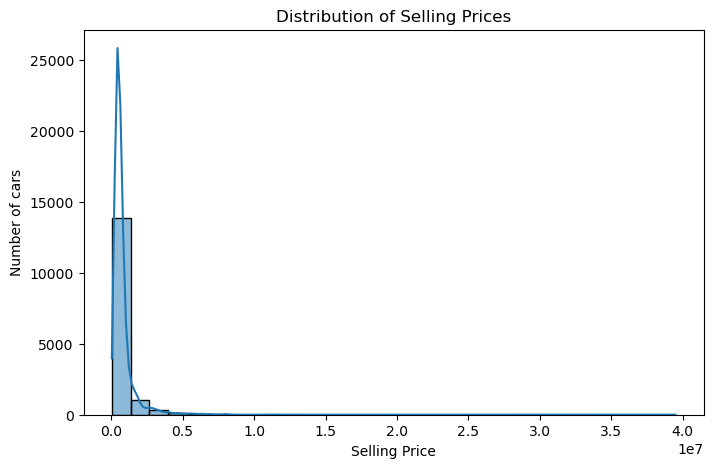

In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(df["selling_price"], bins=30, kde=True)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of cars")
plt.show()

In [34]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

In [48]:
df = pd.read_csv("cardekho_data.csv")      # use your real CSV filename
print(df.columns)                      # look at the real column names

df = df.drop(columns=["Unnamed: 0", "car_name", "brand", "model"])
df = df.drop_duplicates()
df = pd.get_dummies(df, drop_first=True)
print(df.shape)

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')
(15243, 14)


In [49]:
X = df.drop("selling_price", axis=1)
y = df["selling_price"]
print(X.columns)

Index(['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats',
       'seller_type_Individual', 'seller_type_Trustmark Dealer',
       'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG',
       'fuel_type_Petrol', 'transmission_type_Manual'],
      dtype='object')


In [50]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(12194, 13) (3049, 13)


In [51]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [52]:
from sklearn.metrics import mean_absolute_error, r2_score
y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

MAE: 113917.01524350709
R2: 0.7854523885732216


In [53]:
print(df["selling_price"].median())

559000.0


In [54]:
print("Train R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

Train R2: 0.9869117946139069
Test R2: 0.7854523885732216


In [55]:
print("Important Features:", pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

Important Features: max_power                       0.694797
vehicle_age                     0.141506
km_driven                       0.076940
engine                          0.041385
mileage                         0.033029
seller_type_Individual          0.003565
seats                           0.003351
transmission_type_Manual        0.002645
fuel_type_Petrol                0.001454
fuel_type_Diesel                0.001287
seller_type_Trustmark Dealer    0.000027
fuel_type_Electric              0.000011
fuel_type_LPG                   0.000001
dtype: float64


In [58]:
new_car = pd.DataFrame([{
    "max_power": 120,
    "vehicle_age": 5,
    "km_driven": 40000,
    "engine": 1200,
    "mileage": 20,
    "seats": 5,
    "fuel_type_Petrol": True,
    "transmission_type_Manual": True,
    "seller_type_Individual": True,
}])

new_car = new_car.reindex(columns=X.columns, fill_value=0)
print(model.predict(new_car))

[721416.56931957]
